### TEL328 - Procesamiento Digital de Imágenes
# Taller 1

Nombre: PAUTA

## Reglas
1. **Fecha de entrega**:
    - El plazo límite de entrega vence el dia viernes 29/08/2025 a las 23:59.
    - Descuento por atraso: 10 puntos por cada hora.
2. Entregable:
    - La tarea debe ser entregada en un archivo .zip con el formato ```Taller1_Nombre_Apellido.zip```
    - Se debe incluir: 
        - Notebook en formato ```Taller1_Nombre_Apellido.ipynb``` con todo el desarrollo.
        - Imágenes usadas y generadas
        
>**En caso de no cumplir con el formato, se descontará 10 puntos.**

## Introducción

En este taller trabajaremos con un tipo de ruido **no convencional** que degrada severamente la imagen: parches negros colocados en posiciones aleatorias.  

Este tipo de daño **no** se puede resolver eficazmente con filtros lineales o no lineales básicos, ya que no se trata de un ruido aditivo leve, sino de **pérdida total de información** en regiones completas.

El objetivo es diseñar e implementar un **pipeline de restauración (*inpainting*)** usando clustering con **K-Means** para reconstruir las zonas dañadas de manera coherente con su contexto local.

Se espera que:  
- Sepa utilizar librerías estándar para filtrado de imágenes.  
- Diseñe una estrategia de reconstrucción usando K-Means combinando **color** y **posición** como características.  
- Evalúe cuantitativamente y cualitativamente los resultados.  
- Reflexione sobre ventajas, limitaciones y mejoras posibles.

Importaciones

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from skimage import color, metrics, img_as_ubyte

np.random.seed(42)  # Reproducibilidad razonable en el ruido y K-Means

# -------------------------
# Utilidades de visualización
# -------------------------
def show(title, img, cmap=None, size=5):
    """Muestra una imagen con matplotlib; asume RGB uint8 o float en [0,1]."""
    plt.figure(figsize=(size, size))
    if cmap:
        plt.imshow(img, cmap=cmap)
    else:
        plt.imshow(img)
    plt.title(title)
    plt.axis("off")
    plt.show()

def to_uint8(img_float01):
    """Convierte imagen float [0,1] -> uint8 [0,255]."""
    arr = np.clip(img_float01 * 255.0, 0, 255).astype(np.uint8)
    return arr

def ensure_rgb_uint8(img):
    """Se asegura de que la imagen esté en RGB uint8 (conversión si llega en float)."""
    if img.dtype != np.uint8:
        if img.max() <= 1.0:
            return to_uint8(img)
        return img.astype(np.uint8)
    return img

D:\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been deprecated
  "class": algorithms.Blowfish,


### 1) Generar el ruido de cuadrados negros

Se usará el siguiente generador de ruido:

In [2]:
def add_random_squares(image, num_squares, min_size, max_size):
    noisy_image = np.copy(image)
    for _ in range(num_squares):
        size = np.random.randint(min_size, max_size + 1)
        x = np.random.randint(0, image.shape[1] - size)
        y = np.random.randint(0, image.shape[0] - size)
        noisy_image[y:y+size, x:x+size] = 0
    return noisy_image

Tareas:

- Elige una imagen a color (JPG o PNG).

- Genera tres versiones ruidosas con diferentes parámetros.

- Comenta brevemente las diferencias visuales entre cada configuración.

In [3]:
def build_damage_mask(img):
    """
    Genera máscara booleana de daño: True donde hay píxeles (0,0,0).
    Considera imagen RGB uint8.
    """
    return np.all(img == [0, 0, 0], axis=-1)

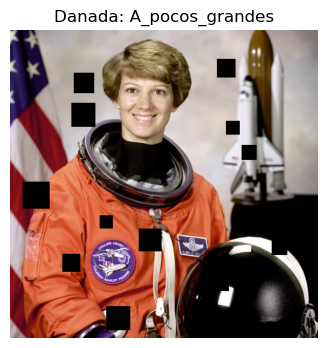

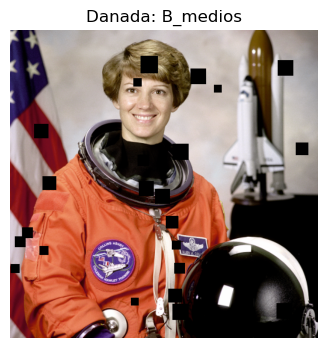

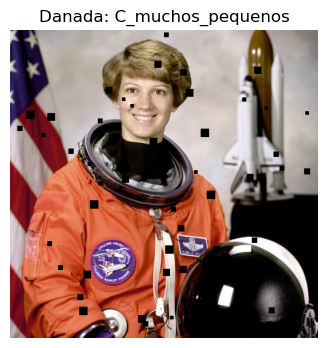

In [4]:
from skimage import data
original = img_as_ubyte(data.astronaut())  # RGB uint8

configs = {
    "A_pocos_grandes":  dict(num_squares=12, min_size=20, max_size=45),
    "B_medios":         dict(num_squares=25, min_size=12, max_size=30),
    "C_muchos_pequenos":dict(num_squares=60, min_size=6,  max_size=14),
}

damaged_images = {}
masks = {}
for name, p in configs.items():
    dmg = add_random_squares(original, **p)
    damaged_images[name] = dmg
    masks[name] = build_damage_mask(dmg)

# Visual de ejemplo
for name, dmg in damaged_images.items():
    show(f"Danada: {name}", dmg, size=4)

*Para el análisis, utilice celdas Markdown.*

### 2) Intento de limpieza con filtros de librería

En esta sección probarás filtros **tradicionales de suavizado** disponibles en **OpenCV**, con el objetivo de observar cómo responden frente al ruido disruptivo introducido en la imagen.

---

#### 2.1. Filtros a implementar
Debes aplicar **al menos 3 filtros distintos**, probando **dos tamaños de ventana** (pequeño y grande) para cada uno. Los filtros sugeridos son:

- **Filtro de media**: `cv2.blur`  
- **Filtro gaussiano**: `cv2.GaussianBlur`  
- **Filtro de mediana**: `cv2.medianBlur`  
- **Filtro bilateral**: `cv2.bilateralFilter`  

> Puedes elegir cuáles aplicar, pero deben ser al menos 3 de la lista.

---

#### 2.2. Comparativa visual
Para cada imagen dañada, genera una figura con **subplots** mostrando:

- Imagen original.  
- Imagen dañada.  
- Resultados con cada filtro (dos versiones: ventana pequeña y ventana grande).  

Ejemplo de layout esperado:

| Original | Dañada | Media (5×5) | Media (15×15) |
|----------|--------|-------------|---------------|
| Gauss (5×5) | Gauss (15×15) | Mediana (5) | Mediana (15) |

---

#### 2.3. Evaluación con MAE
- Calcula el **MAE (Mean Absolute Error)** entre la imagen original y cada resultado filtrado, **solo en la región dañada** definida por la máscara.  
- Registra los valores de MAE en una tabla o imprime un resumen en consola.  
- Identifica cuál fue el **mejor filtro** (menor MAE).  

---

#### 2.4. Discusión crítica
- Explica **por qué los filtros tradicionales no funcionan bien** en este escenario.

- Responde las siguientes preguntas:
  - ¿Qué filtro fue más robusto frente a los cuadrados negros?  
  - ¿Qué efecto tuvo aumentar el tamaño de la ventana?  
  - ¿Se observó algún trade-off entre calidad visual y error numérico (MAE)?  

In [5]:
def try_library_filters(img_damaged):
    """
    Aplica varios filtros de OpenCV (librería) para intentar "limpiar" la imagen.
    Devuelve un dict con resultados y los parámetros usados (para comparación).
    """
    results = {}

    # --- Media (box filter) ---
    results["mean_5"]  = cv2.blur(img_damaged, (5, 5))
    results["mean_15"] = cv2.blur(img_damaged, (15, 15))

    # --- Gaussiano ---
    results["gauss_5"]  = cv2.GaussianBlur(img_damaged, (5, 5), 0)
    results["gauss_15"] = cv2.GaussianBlur(img_damaged, (15, 15), 0)

    # --- Mediana ---
    # Nota: medianBlur requiere un tamaño impar; soporta imágenes de 1 o 3 canales.
    results["median_5"]  = cv2.medianBlur(img_damaged, 5)
    results["median_15"] = cv2.medianBlur(img_damaged, 15)

    # --- Bilateral (suaviza preservando bordes) ---
    # d: diámetro del vecindario; sigmaColor y sigmaSpace controlan el filtrado.
    results["bilateral_9"]  = cv2.bilateralFilter(img_damaged, d=9, sigmaColor=75, sigmaSpace=75)
    results["bilateral_15"] = cv2.bilateralFilter(img_damaged, d=15, sigmaColor=75, sigmaSpace=75)

    return results

In [12]:
def show_filtered_results(damaged_img, filtered_dict, case_name="Caso"):
    """
    Muestra resultados de todos los filtros aplicados a una imagen dañada,
    usando subplots en mosaico (2 filas × N columnas).
    
    - damaged_img: imagen dañada (RGB)
    - filtered_dict: dict {nombre_filtro: imagen_filtrada}
    - case_name: título del caso para mostrar
    """
    n = len(filtered_dict)
    cols = 4
    rows = int(np.ceil(n / cols)) + 1  # +1 para incluir la imagen dañada
    plt.figure(figsize=(4*cols, 4*rows))
    
    # Imagen dañada en la primera celda
    plt.subplot(rows, cols, 1)
    plt.imshow(damaged_img)
    plt.title(f"Dañada - {case_name}")
    plt.axis("off")
    
    # Filtros
    for i, (fname, fimg) in enumerate(filtered_dict.items(), start=2):
        plt.subplot(rows, cols, i)
        plt.imshow(fimg)
        plt.title(fname)
        plt.axis("off")
    
    plt.tight_layout()
    plt.show()

In [6]:
filtered_results = {name: try_library_filters(dmg) for name, dmg in damaged_images.items()}

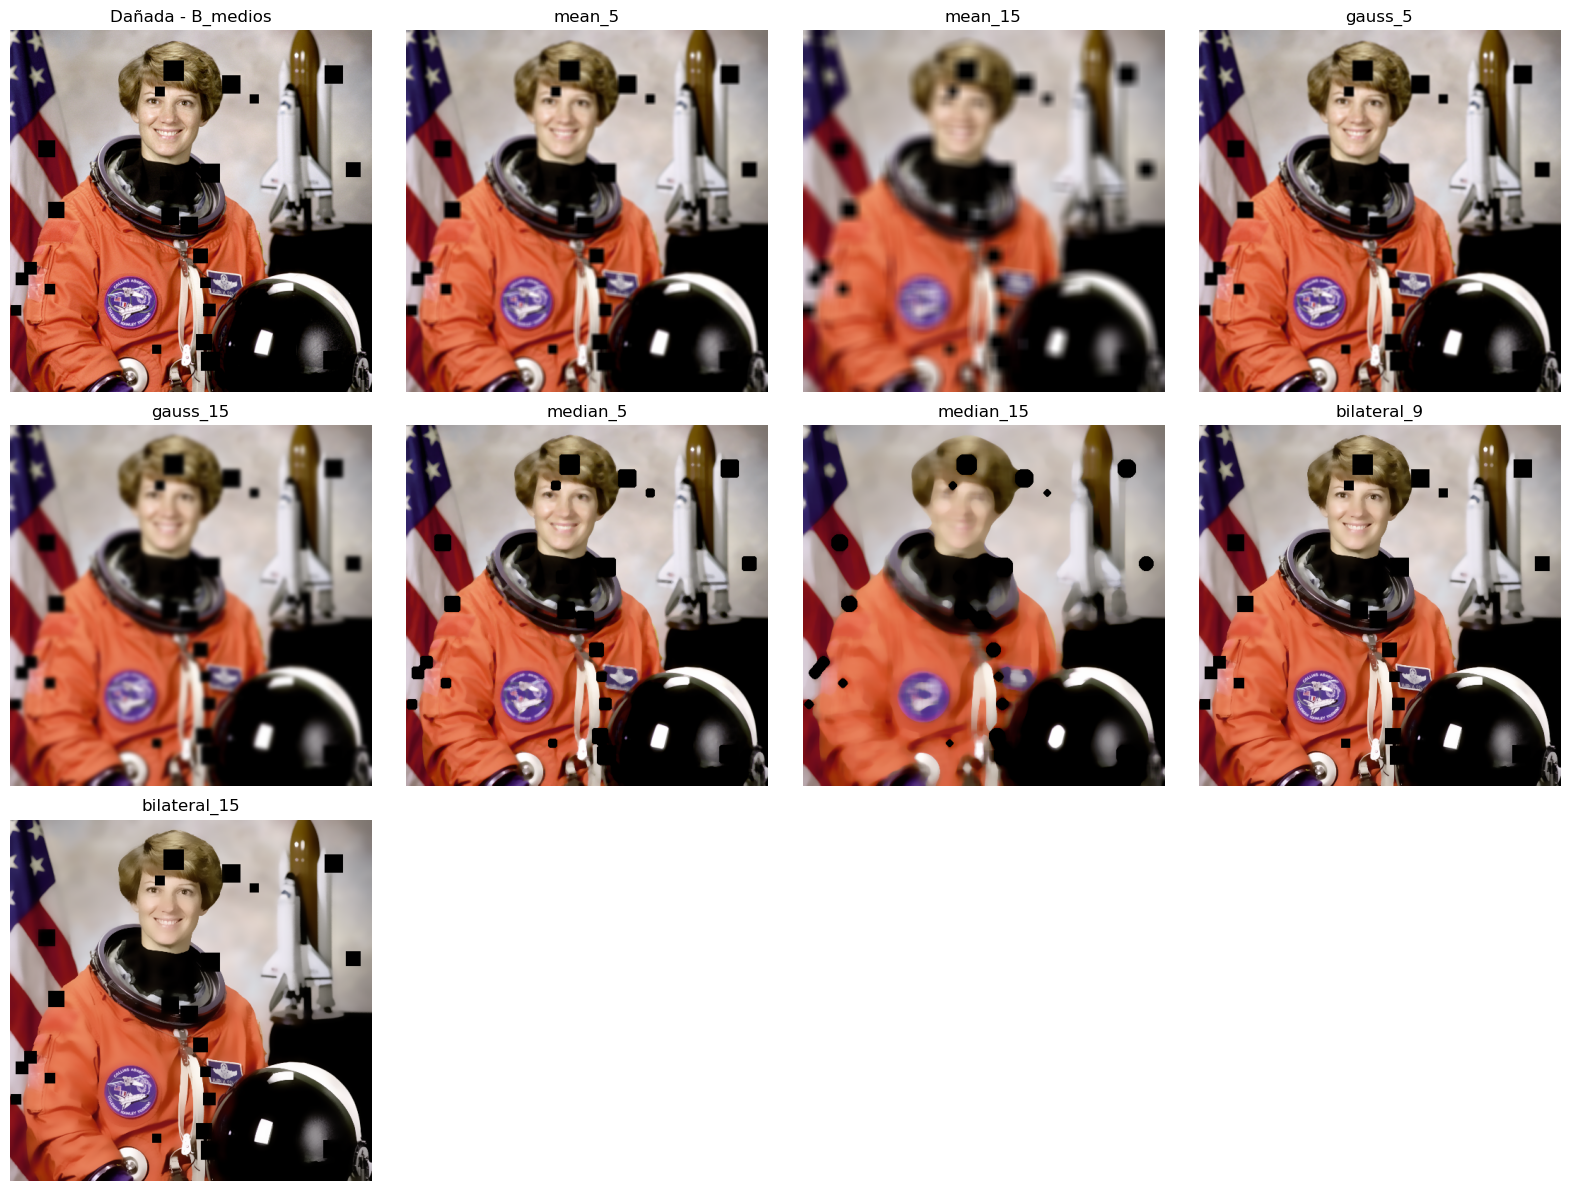

In [13]:
case = "B_medios"
show_filtered_results(damaged_images[case], filtered_results[case], case_name=case)

*Para el análisis, utilice celdas Markdown.*

### 3) Restauración por inpainting con K-Means

En esta sección deberás implementar un algoritmo de **inpainting** basado en **clustering K-Means**, con el objetivo de reconstruir las zonas dañadas por cuadrados negros. 

El proceso se divide en varias etapas:

---

#### 3.1. Crear máscara de daño
- Detecta los píxeles negros `(0,0,0)` en la imagen dañada.  
- Construye una **máscara binaria** donde `1` indica píxeles dañados y `0` píxeles intactos.  
- Esta máscara será usada para distinguir qué píxeles entran al entrenamiento y cuáles deben reconstruirse.

---

#### 3.2. Espacio de características
- Convierte la imagen al espacio de color **Lab** (mejor para representar similitud perceptual).  
- Para cada píxel, crea un vector de características de la forma:  

  \[
  f = [L, a, b, \lambda x, \lambda y]
  \]

  donde:
  - `(L,a,b)` corresponden a los valores Lab.  
  - `(x,y)` son las coordenadas normalizadas entre 0 y 1.  
  - `λ` es un factor de ponderación entre `0.1` y `0.5` que controla cuánto influye la posición espacial.  

- Ajusta `λ` y observa cómo cambia la reconstrucción.

---

#### 3.3. Entrenar K-Means solo con píxeles intactos
- Extrae únicamente los **píxeles intactos** (los que no son negros).  
- Aplica **K-Means** para agrupar estos píxeles en `k` clusters.  
- Prueba al menos dos valores de `k` (ejemplo: `k=4` y `k=8`).  
- Cada cluster tendrá un **centroide Lab**, que representa un color promedio de una región de la imagen.

---

#### 3.4. Rellenar zonas dañadas
- Para cada píxel dañado:  
  - Define una **ventana local** (ej. 7×7, 11×11, etc.).  
  - Determina el **cluster dominante** en la vecindad (ignora los píxeles dañados).  
  - Asigna al píxel el **color del centroide** de ese cluster.  

- Si no hay suficientes vecinos válidos, asigna el cluster más frecuente de toda la imagen.

---

#### 3.5. Suavizado de bordes
- Una vez reconstruida la imagen, aplica un **suavizado en la zona de transición** (por ejemplo, con un **filtro bilateral**) para reducir artefactos.  
- El suavizado debe aplicarse principalmente en los bordes entre zonas intactas y reconstruidas.

---

#### 3.6. Evaluar resultados
- Usa la **métrica MAE (Mean Absolute Error)**, restringida a la región dañada definida por la máscara.  

- Compara:
  - El **mejor filtro** de la sección 2 (el que haya dado menor MAE).  
  - El **inpainting con K-Means**.  

- Presenta los resultados de dos formas:
  1. **Tabla en consola** con los valores de MAE para cada caso.  
  2. **Subplots comparativos** mostrando:  
     - Imagen original.  
     - Imagen dañada.  
     - Resultado del mejor filtro.  
     - Resultado del inpainting con K-Means.  

  Ejemplo de mosaico esperado:  

  | Original | Dañada | Mejor filtro | K-Means |
  |----------|--------|--------------|---------|

- Discute cuál método logra menor error y si visualmente corresponde con la calidad percibida.

---

#### 3.7. Discusión crítica
- Reflexiona sobre:
  - ¿Qué valor de `k` funcionó mejor y por qué?  
  - ¿Cómo influyó el parámetro `λ` en la reconstrucción?  
  - ¿Qué limitaciones tiene este método frente a técnicas de inpainting avanzadas?  
  - ¿Qué mejoras podrías proponer? (ejemplo: usar información de texturas, interpolación espacial más sofisticada, redes neuronales, etc.).  


In [19]:
def lab_pos_features(img_rgb, lam_pos=0.3):
    H, W = img_rgb.shape[:2]
    lab = color.rgb2lab(img_rgb)
    yy, xx = np.meshgrid(np.linspace(0, 1, H), np.linspace(0, 1, W), indexing="ij")
    coords = np.stack([xx, yy], axis=-1).reshape(-1, 2)
    L = lab[..., 0].reshape(-1, 1)
    a = lab[..., 1].reshape(-1, 1)
    b = lab[..., 2].reshape(-1, 1)
    Xpos = (lam_pos * coords)
    feats = np.concatenate([L, a, b, Xpos], axis=1).astype(np.float64)
    return feats, coords, lab

def standardize_feats(feats, mask_valid):
    valid_feats = feats[mask_valid]
    mu = valid_feats.mean(axis=0)
    std = valid_feats.std(axis=0) + 1e-8
    feats_z = (feats - mu) / std
    return feats_z, (mu, std)

def kmeans_fit_on_intact(feats_z, mask_valid, k=8, random_state=42, n_init=10):
    km = KMeans(n_clusters=k, random_state=random_state, n_init=n_init)
    labels_intact = km.fit_predict(feats_z[mask_valid])
    return km, labels_intact

def build_cluster_color_table(lab_img, mask_valid, labels_intact, k):
    H, W = lab_img.shape[:2]
    label_map = np.full((H, W), -1, dtype=np.int32)
    idx_intact = np.flatnonzero(mask_valid)
    ys = idx_intact // W
    xs = idx_intact % W
    label_map[ys, xs] = labels_intact

    cluster_lab_mean = np.zeros((k, 3), dtype=np.float64)
    for c in range(k):
        sel = (labels_intact == c)
        if np.any(sel):
            ys_c = ys[sel]
            xs_c = xs[sel]
            cluster_lab_mean[c] = lab_img[ys_c, xs_c].mean(axis=0)
        else:
            cluster_lab_mean[c] = lab_img[mask_valid.reshape(H, W)].mean(axis=0)
    return cluster_lab_mean, label_map

def dominant_label_in_window(label_patch):
    valid = label_patch[label_patch >= 0]
    if valid.size == 0:
        return None
    vals, counts = np.unique(valid, return_counts=True)
    return vals[np.argmax(counts)]

def inpaint_kmeans(img_damaged, lam_pos=0.3, k=8,
                   win_sizes=(7, 11, 15, 21),
                   min_samples_in_win=20,
                   smooth_border=True,
                   bilateral_params=(9, 50, 50)):
    img = ensure_rgb_uint8(img_damaged)
    H, W = img.shape[:2]
    mask_damage = build_damage_mask(img)

    feats, coords, lab = lab_pos_features(img, lam_pos=lam_pos)
    mask_valid = ~mask_damage.reshape(-1)
    feats_z, _ = standardize_feats(feats, mask_valid)
    km, labels_intact = kmeans_fit_on_intact(feats_z, mask_valid, k=k)
    cluster_lab_mean, label_map = build_cluster_color_table(lab, mask_valid, labels_intact, k)

    lab_restore = lab.copy()
    idx_damage = np.flatnonzero(mask_damage.reshape(-1))
    ys_d = idx_damage // W
    xs_d = idx_damage % W
    global_mode = np.bincount(labels_intact).argmax()

    for y, x in zip(ys_d, xs_d):
        chosen_label = None
        for w in win_sizes:
            r = w // 2
            y0, y1 = max(0, y - r), min(H, y + r + 1)
            x0, x1 = max(0, x - r), min(W, x + r + 1)
            label_patch = label_map[y0:y1, x0:x1]
            if (label_patch >= 0).sum() >= min_samples_in_win:
                chosen_label = dominant_label_in_window(label_patch)
                if chosen_label is not None:
                    break
        if chosen_label is None:
            chosen_label = global_mode
        lab_restore[y, x] = cluster_lab_mean[chosen_label]

    rgb_restored = to_uint8(np.clip(color.lab2rgb(lab_restore), 0, 1))
    if smooth_border:
        mask_u8 = (mask_damage.astype(np.uint8) * 255)
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
        border = cv2.morphologyEx(mask_u8, cv2.MORPH_GRADIENT, kernel)
        d, sC, sS = bilateral_params
        smoothed = cv2.bilateralFilter(rgb_restored, d=d, sigmaColor=sC, sigmaSpace=sS)
        border_3c = (border > 0)[..., None]
        rgb_restored = np.where(border_3c, smoothed, rgb_restored)
    return rgb_restored

*Para el análisis, utilice celdas Markdown.*

In [16]:
def masked_mae(a, b, mask):
    a = ensure_rgb_uint8(a).astype(np.float64)
    b = ensure_rgb_uint8(b).astype(np.float64)
    m = mask.astype(bool)
    if m.sum() == 0:
        return 0.0
    diff = np.abs(a[m] - b[m])
    return float(diff.mean())


=== RESUMEN DE MAE (solo región dañada) ===

Caso: A_pocos_grandes
  Mejor filtro: mean_15 | MAE = 39.39
  Inpainting KMeans | MAE = 91.53


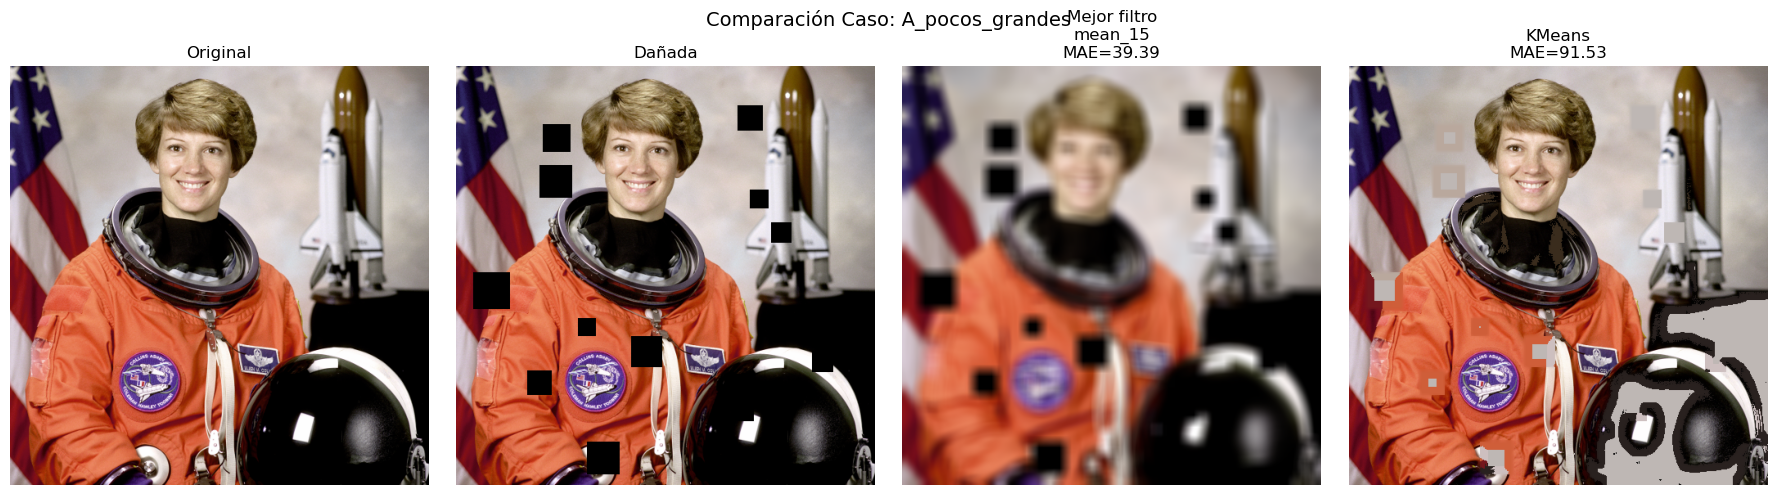


Caso: B_medios
  Mejor filtro: mean_15 | MAE = 24.68
  Inpainting KMeans | MAE = 94.11


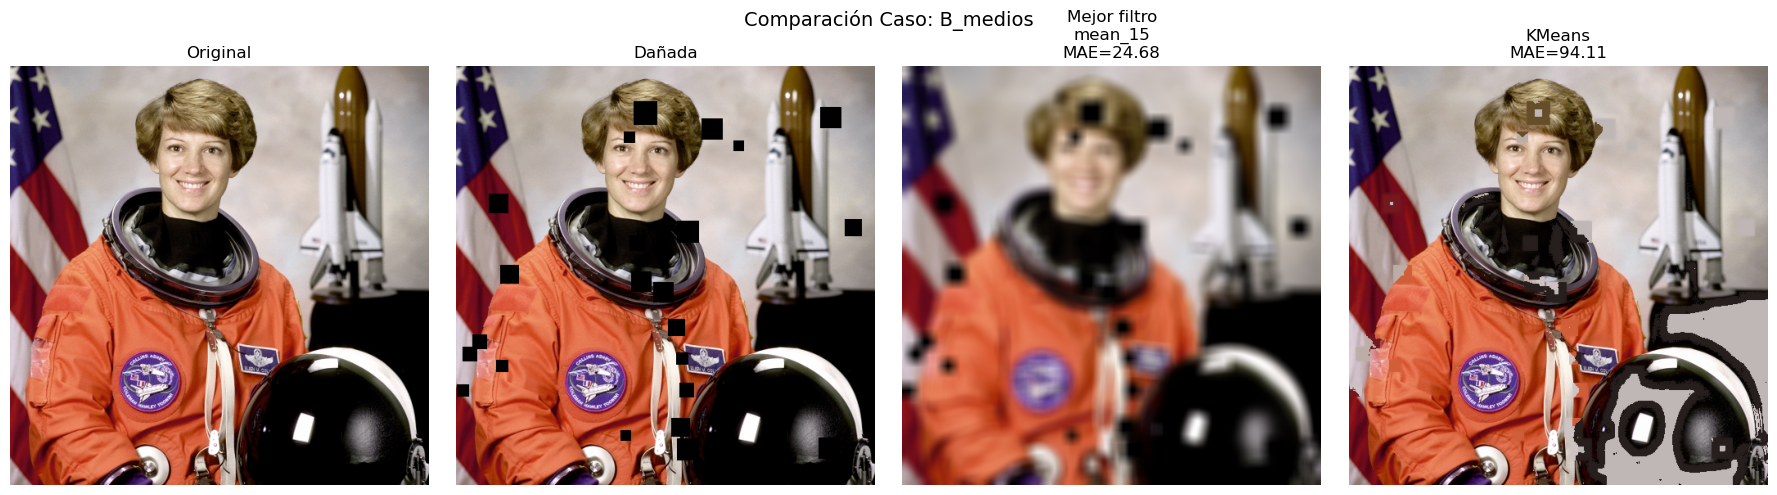


Caso: C_muchos_pequenos
  Mejor filtro: median_15 | MAE = 9.30
  Inpainting KMeans | MAE = 101.64


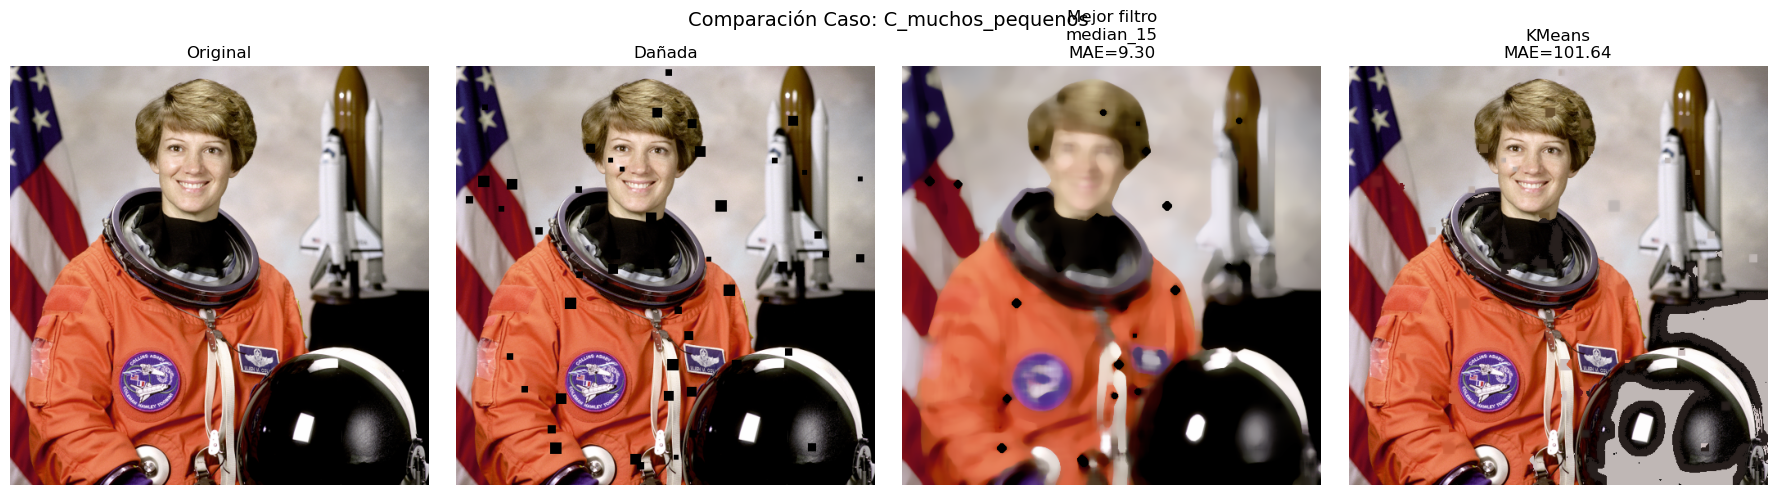

In [21]:
inpainted_results = {}
for name, dmg in damaged_images.items():
    restored = inpaint_kmeans(dmg, lam_pos=0.3, k=8)
    inpainted_results[name] = restored

# Comparación de MAE
print("\n=== RESUMEN DE MAE (solo región dañada) ===")
for name in configs.keys():
    mae_filters = {fname: masked_mae(original, fimg, masks[name]) for fname, fimg in filtered_results[name].items()}
    best_f = min(mae_filters, key=mae_filters.get)
    mae_inp = masked_mae(original, inpainted_results[name], masks[name])
    print(f"\nCaso: {name}")
    print(f"  Mejor filtro: {best_f} | MAE = {mae_filters[best_f]:.2f}")
    print(f"  Inpainting KMeans | MAE = {mae_inp:.2f}")

    # ---- Subplots comparativos ----
    fig, axs = plt.subplots(1, 4, figsize=(18, 5))
    axs[0].imshow(original)
    axs[0].set_title("Original")
    axs[0].axis("off")

    axs[1].imshow(damaged_images[name])
    axs[1].set_title("Dañada")
    axs[1].axis("off")

    axs[2].imshow(filtered_results[name][best_f])
    axs[2].set_title(f"Mejor filtro\n{best_f}\nMAE={mae_filters[best_f]:.2f}")
    axs[2].axis("off")

    axs[3].imshow(inpainted_results[name])
    axs[3].set_title(f"KMeans\nMAE={mae_inp:.2f}")
    axs[3].axis("off")

    plt.suptitle(f"Comparación Caso: {name}", fontsize=14)
    plt.tight_layout()
    plt.show()

*Para el análisis, utilice celdas Markdown.*

### Ejemplo visual del problema a resolver

La siguiente figura muestra un ejemplo de la situación a abordar:

| Imagen original | Imagen dañada (ruido de cuadrados negros) | Ejemplo de restauración |
|-----------------|--------------------------------------------|--------------------------|
| ![Original](original.jpg) | ![Dañada](danada.jpg) | ![Restaurada](restaurada.jpg) |

- **Original:** Imagen sin alteraciones.
- **Dañada:** Ruido disruptivo por cuadrados negros aleatorios.
- **Restaurada:** Ejemplo ilustrativo de reconstrucción (*inpainting*) basada en información de la propia imagen.

> Nota: El resultado mostrado es solo una referencia conceptual. Tu implementación deberá producir su propia versión restaurada, que puede diferir en detalles y calidad.


### Entregables

- Imágenes original y ruidosas.

- Resultados de filtros de librería con análisis.

- Implementación y resultados del pipeline K-Means con visualizaciones intermedias.

- Métricas cuantitativas.

- Conclusiones.